# Predicción de abandono de clientes (Customer Churn)

**Objetivo:** construir un modelo predictivo exploratorio que identifique qué clientes de una empresa de telecomunicaciones tienen mayor probabilidad de abandonar el servicio, y explicar sus resultados y limitaciones en términos de negocio.

**Dataset:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — 7,043 clientes y 21 columnas.

**Contenido**
1. Carga y exploración inicial
2. Análisis exploratorio (EDA)
3. Preprocesamiento y partición train/test
4. Escalado de variables numéricas
5. Modelado (regresión logística, Random Forest, class_weight)
6. Selección del umbral de decisión (validación cruzada)
7. Evaluación final en test
8. Comparación de modelos
9. Conclusión y limitaciones

## 0. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    fbeta_score, confusion_matrix, classification_report
)

## 1. Carga y exploración inicial del dataset

Se carga el dataset de Telco Customer Churn y hacemos una primera inspección: dimensiones, tipos de datos y valores faltantes.

In [2]:
df = pd.read_csv('dataset/Telco-Customer-Churn.csv')
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
df.head()

Filas: 7043, Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Información general: tipos de datos y nulos

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# Intentar convertir TotalCharges a numérico
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Ver cuántos valores quedaron como nulos tras la conversión
print(f"Valores nulos en TotalCharges: {df['TotalCharges'].isnull().sum()}")

df[df['TotalCharges'].isnull()]

Valores nulos en TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [5]:
# Rellenar los nulos de TotalCharges con 0 (clientes con tenure = 0)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verificar que ya no queden nulos
print(f"Valores nulos restantes: {df['TotalCharges'].isnull().sum()}")
print(f"Tipo de dato actual: {df['TotalCharges'].dtype}")

Valores nulos restantes: 0
Tipo de dato actual: float64


**Nota:** Se encontraron 11 registros con 'TotalCharges' vacío, todos correspondientes a clientes con 'tenure = 0' (recién adquiridos, sin facturación acumulada aún). Se decidió imputar estos valores con 0 porque representa la realidad del dato: no es un valor faltante, sino un valor nulo (todavía no han pagado nada).

## 2. Análisis exploratorio (EDA): variable objetivo 'Churn'

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


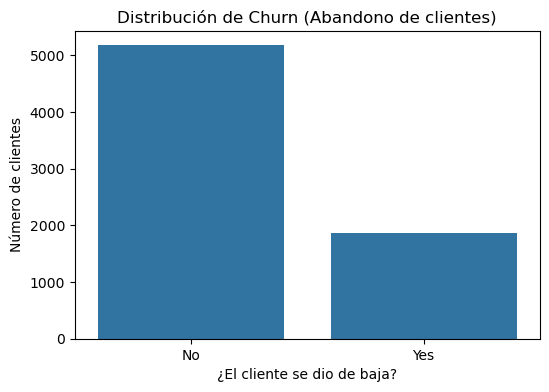

In [6]:
#Distribución absoluta y porcentual de la variable objetivo
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True) * 100)

#Visualización de la distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Distribución de Churn (Abandono de clientes)')
plt.xlabel('¿El cliente se dio de baja?')
plt.ylabel('Número de clientes')
plt.show()

**Observación:** El dataset presenta un desbalance de clases moderado (73% No / 27% Yes). Esto significa que el accuracy por sí solo no será suficiente para evaluar el modelo, se dará prioridad a precision, recall y F1-score sobre la clase "Yes" (clientes que abandonan), ya que es la clase de interés para el negocio.

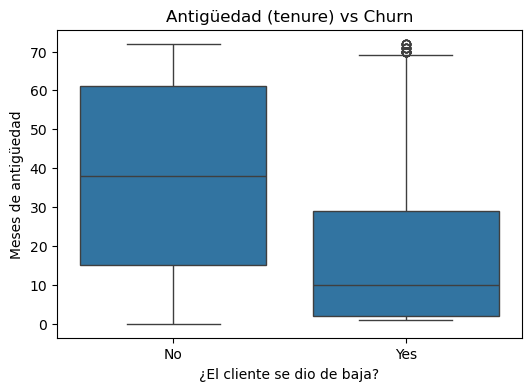

In [7]:
#Relación entre antigüedad del cliente (tenure) y abandono
plt.figure(figsize=(6, 4))
sns.boxplot(data = df, x = 'Churn', y = 'tenure')
plt.title('Antigüedad (tenure) vs Churn')
plt.xlabel('¿El cliente se dio de baja?')
plt.ylabel('Meses de antigüedad')
plt.show()

Los clientes que abandonan ('Churn = Yes') tienen una antigüedad mediana mucho menor (10 meses) que los que permanecen (38 meses). Esto sugiere que 'tenure' será una variable altamente predictiva y, desde la perspectiva de negocio, indica que el riesgo de abandono es mayor en los primeros meses de vida del cliente.

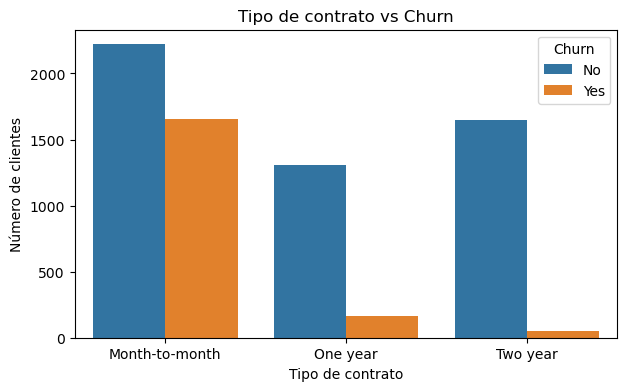

In [8]:
# Relación entre tipo de contrato y abandono
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Tipo de contrato vs Churn')
plt.xlabel('Tipo de contrato')
plt.ylabel('Número de clientes')
plt.show()

El abandono se concentra fuertemente en clientes con contrato mes a mes, mientras que los contratos de un año y aún más los de 2 años presentan tasas de abandono muy bajas. Esto sugiere que 'Contract' será otra variable importante para el modelo, y refuerza la idea de incentivar contratos más largos (descuentos, beneficios) podría reducir el abandono.

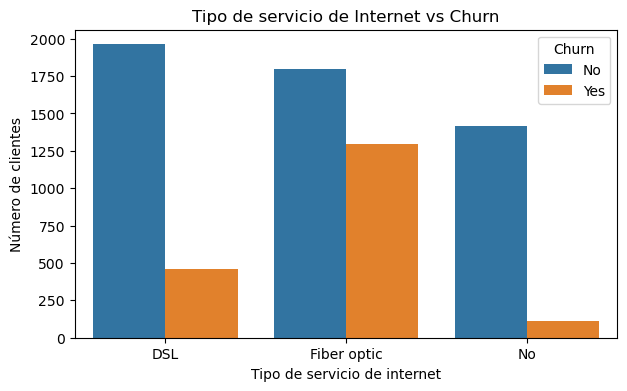

In [9]:
#Relación entre tipo de servicio de internet y abandono
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.title('Tipo de servicio de Internet vs Churn')
plt.xlabel('Tipo de servicio de internet')
plt.ylabel('Número de clientes')
plt.show()

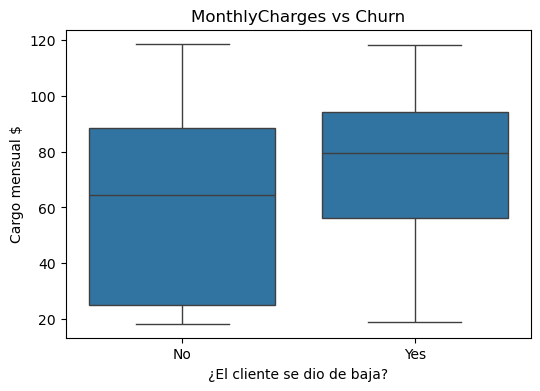

In [10]:
#Relación entre cargo mensual y abandono
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('MonthlyCharges vs Churn')
plt.xlabel('¿El cliente se dio de baja?')
plt.ylabel('Cargo mensual $')
plt.show()

### Resumen del EDA

Se identificaron 4 variables con relación clara al abandono de clientes:

1. **'tenure':** los clientes que abandonan tienen una antigüedad mediana mucho menor (10 meses) que los que permanecen (38 meses). El riesgo de churn es mayor en los primeros meses de vida del cliente.
2. **'Contract':** el abandono se concentra principalmente en contratos mes a mes, mientras que los contratos de uno o dos años presentan un churn mínimo.
3. **'InternetService':** los clientes con fibra óptica presentan la tasa de abandono más alta, superando a DSL, a pesar de ser el servicio premium.
4. **'MonthlyCharges':** los clientes que abandonan pagan en mediana más (≈ $65–$80), lo que sugiere sensibilidad al precio, especialmente en el segmento de fibra óptica.

**Conclusión:** el perfil de mayor riesgo de abandono es un cliente nuevo, con contrato mes a mes, servicio de fibra óptica y cargo mensual alto. Esto da una base clara para las siguientes etapas: construir un modelo predictivo y, más importante, diseñar acciones de retención dirigidas a este segmento.

## 3. Preprocesamiento y partición train/test

In [11]:
#Eliminación de columna que no aporta valor predictivo
df_model = df.drop('customerID', axis=1) 

#Separación de la variable objetivo (y) y se convierte a formato númerico
y = df_model['Churn'].map({'Yes': 1, 'No': 0})

#Features: todas las columnas excepto la variable objetivo.
x = df_model.drop('Churn', axis=1)

#Codificar variables categóricas con One-Hot encoding
#Convierte cada categoría de texto en una columna binaria 0/1.
#drop_first=True elimina una categoria por variable para evitar redundancia
x = pd.get_dummies(x, drop_first=True)

print(f"Shape de X: {x.shape}")
x.head()

Shape de X: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [12]:
#80% entrenamiento/ 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y          #Mantiene la misma proporcion de Churn en ambos sets
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

#Verifico que la proprorción de clases se mantuvo en Train y Test
print(f"Proporción de Churn en train:\n{y_train.value_counts(normalize=True)}")
print(f"Proporción de Churn en test:\n{y_test.value_counts(normalize=True)}")

X_train: (5634, 30)
X_test: (1409, 30)
Proporción de Churn en train:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Proporción de Churn en test:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## 4. Escalado de variables numéricas

Se ajusta el 'StandardScaler' **solo con el conjunto de entrenamiento** ('fit_transform') y se aplica al de prueba con 'transform', para evitar fuga de información (*data leakage*).

In [13]:
#Identificando las columnas numéricas que necesitan escalado 
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

#Copias para no alterar los DataFrames originales
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print(X_train_scaled[numeric_cols].describe())

             tenure  MonthlyCharges  TotalCharges
count  5.634000e+03    5.634000e+03  5.634000e+03
mean  -1.008935e-17   -2.402527e-16  2.522338e-17
std    1.000089e+00    1.000089e+00  1.000089e+00
min   -1.322329e+00   -1.544028e+00 -1.008922e+00
25%   -9.559779e-01   -9.711977e-01 -8.321009e-01
50%   -1.418632e-01    1.848336e-01 -3.968446e-01
75%    9.164859e-01    8.319124e-01  6.741944e-01
max    1.608483e+00    1.785939e+00  2.801869e+00


## 5. Modelado

### Modelo 0: regresión logística sin escalar (referencia)

Se entrena con las variables sin escalar. Genera una 'ConvergenceWarning' porque 'tenure', 'MonthlyCharges' y 'TotalCharges' tienen escalas muy distintas al resto de columnas (0/1); esto motiva el escalado del paso anterior.

In [14]:
#Creando y entendiendo el modelo
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

#Generando predicciones sobre el set de prueba
y_pred = model.predict(X_test)

print("El modelo se entreno de forma correcta.")
print(f"Primeras 10 predicciones: {y_pred[:10]}")
print(f"Primeros 10 valores reales: {y_test[:10].values}")

El modelo se entreno de forma correcta.
Primeras 10 predicciones: [0 1 0 0 0 1 0 0 0 0]
Primeros 10 valores reales: [0 0 0 0 0 0 0 0 0 1]


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Modelo 1: regresión logística (con escalado)

In [15]:
#Creando y entendiendo el modelo
model_scaled = LogisticRegression(max_iter=1000, random_state=42)
model_scaled.fit(X_train_scaled, y_train)

#Generando predicciones con los datos escalados
y_pred_scaled = model_scaled.predict(X_test_scaled)

print("El modelo se entreno de forma correcta.")
print(f"Primeras 10 predicciones: {y_pred_scaled[:10]}")
print(f"Primeros 10 valores reales: {y_test[:10].values}")

El modelo se entreno de forma correcta.
Primeras 10 predicciones: [0 1 0 0 0 1 0 0 0 0]
Primeros 10 valores reales: [0 0 0 0 0 0 0 0 0 1]


In [16]:
#Calcular las metricas principales
accuracy = accuracy_score(y_test, y_pred_scaled)
precision = precision_score(y_test, y_pred_scaled)
recall = recall_score(y_test, y_pred_scaled)
f1 = f1_score(y_test, y_pred_scaled)

print(f"Accuracy: {accuracy: .4f}")
print(f"Precision: {precision: .4f}")
print(f"Recall: {recall: .4f}")
print(f"F1-score: {f1: .4f}")
print()

#Reporte completo con metricas por clase
print(classification_report(y_test, y_pred_scaled))

#Matriz de confusión
cm = confusion_matrix(y_test, y_pred_scaled)
print("Matriz de confusión:")
print(cm)

Accuracy:  0.8062
Precision:  0.6593
Recall:  0.5588
F1-score:  0.6049

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Matriz de confusión:
[[927 108]
 [165 209]]


## Evaluación del modelo base (Regresión Logística)

El modelo alcanza un accuracy de 80.6%, pero esta métrica es poco informativa 
dado el desbalance de clases. Las métricas relevantes para el negocio son:

- **Precision (Yes): 66%** — de cada 10 alertas de posible cancelación, 
  ~6-7 son clientes que realmente se iban a ir.
- **Recall (Yes): 56%** — de cada 10 clientes que realmente cancelan, 
  el modelo solo detecta a ~5-6; el resto (44%) pasa desapercibido.

**Limitación clave:** el modelo tiene un sesgo hacia la clase mayoritaria 
("No cancela"), por lo que es conservador al predecir churn. Esto significa 
que, en su estado actual, una estrategia de retención basada en este modelo 
dejaría sin intervención a casi la mitad de los clientes que realmente 
están en riesgo de irse.

### Modelo 2: Random Forest

In [17]:
rf_model = RandomForestClassifier(n_estimators= 200, max_depth=10, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.8041
Precision: 0.6644
Recall: 0.5294
F1-score: 0.5893
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409

[[935 100]
 [176 198]]


Random Forest (200 árboles, 'max_depth=10') no mejora a la regresión logística: accuracy y recall son prácticamente iguales (recall ≈ 53% vs 56%). Un modelo más complejo no resolvió el problema de fondo, que es el **desbalance de clases** y el umbral de decisión, no la capacidad del modelo. Por eso se prueba a continuación ajustar el peso de las clases.

### Modelo 3: regresión logística con 'class_weight="balanced"'

In [18]:
#Regresión logistica con peso balanceado entre clases

model_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

model_balanced.fit(X_train_scaled, y_train)
y_pred_balanced = model_balanced.predict(X_test_scaled)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_balanced):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_balanced):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_balanced):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_balanced):.4f}")
print(confusion_matrix(y_test, y_pred_balanced))

Accuracy:  0.7381
Precision: 0.5043
Recall:    0.7834
F1-score:  0.6136
[[747 288]
 [ 81 293]]


El recall subio de 56% a 78%. Se detecta 293 de los 374 churners, contra 209 antes: 84 clientes más que se iban ahora quedan identificados y los falsos negativos bajaron de 165 a 81.

El costo: la precisión cayo del 66% al 50%. Los falsos positivos subieron de 108 a 288 esto implica 180 falsas alarmas más. De cada 10 alertas, solo 5 son churners reales.

El accuracy bajo del 81% al 74%. El modelo empeoro en esa metrica pero es más útil si el objetivo es retener clientes.

El F1 casi no cambio del 0.605 a 0.614. Esto es normal ya que F1 pondera precision y recall igual.

## 6. Selección del umbral de decisión

In [19]:
# 5 particiones del train, estratificadas para conservar la proporción de churn
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Probabilidad de churn para cada cliente del train, calculada por un modelo
# que NO vio a ese cliente durante su entrenamiento
y_proba_cv = cross_val_predict(
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_scaled, y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

# Probar umbrales de 0.20 a 0.60
umbrales = np.arange(0.20, 0.61, 0.05)
filas = []
for u in umbrales:
    y_pred_u = (y_proba_cv >= u).astype(int)
    filas.append({
        'Umbral': round(u, 2),
        'Precision': precision_score(y_train, y_pred_u),
        'Recall': recall_score(y_train, y_pred_u),
        'F1': f1_score(y_train, y_pred_u),
        'F2': fbeta_score(y_train, y_pred_u, beta=2)
    })

tabla_cv = pd.DataFrame(filas).set_index('Umbral').round(4)
tabla_cv

,Precision,Recall,F1,F2
Umbral,,,,
0.20,0.4746,0.8548,0.6103,0.7368
0.25,0.5096,0.8167,0.6276,0.7289
0.30,0.5421,0.7659,0.6349,0.7075
0.35,0.5697,0.7164,0.6347,0.6813
0.40,0.5940,0.6635,0.6269,0.6484
0.45,0.6237,0.6020,0.6127,0.6062
0.50,0.6538,0.5445,0.5942,0.5633
0.55,0.6853,0.4836,0.5671,0.5139
0.60,0.7100,0.3946,0.5073,0.4331




El umbral por defecto (0.5) produce un recall de ~54% en validación cruzada: 
casi la mitad de los clientes que abandonan pasa sin ser detectada. 

Se evaluaron umbrales de 0.20 a 0.60 mediante validación cruzada estratificada 
(5 particiones) sobre el conjunto de entrenamiento, sin usar el conjunto de prueba. 
Se eligió **0.35** porque su F1 es prácticamente igual al máximo (0.635) y, frente 
a 0.30, reduce las falsas alarmas manteniendo un recall superior al 70%.

**Supuesto de negocio:** este umbral asume que contactar a un cliente que no se 
iba cuesta menos que perder a uno que sí. Si el costo de retención fuera alto, 
convendría un umbral mayor.

## 7. Evaluación final en el conjunto de prueba

Una vez elegido el umbral con validación cruzada (sin tocar el test), se evalúa una sola vez sobre el conjunto de prueba.

In [20]:
#Umbral elegido con validación cruzada
umbral_elegido = 0.35

#Aplicando probabilidad de churn para cada cliente del test,
#usando el modelo ya entrenado con train.
y_proba_test = model_scaled.predict_proba(X_test_scaled)[:,1]

#Convirtiendo probabilidades en clases con el umbral elegido.
y_pred_final = (y_proba_test >= umbral_elegido).astype(int)

#Metricas finales
print(f"Umbral: {umbral_elegido}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_final):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_final):.4f}")
print()
print(classification_report(y_test, y_pred_final))
print(confusion_matrix(y_test, y_pred_final))

Umbral: 0.35
Accuracy: 0.7651
Precision: 0.5445
Recall: 0.7032
F1-score: 0.6138

              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.54      0.70      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.77      1409

[[815 220]
 [111 263]]


## 8. Comparación de modelos

Tabla resumen de las métricas (clase 'Yes') de los cuatro enfoques sobre el conjunto de prueba.

In [21]:
# Diccionario: nombre del modelo -> sus predicciones sobre el test
predicciones = {
    'Logística (umbral 0.5)':  y_pred_scaled,
    'Random Forest':           y_pred_rf,
    'Logística balanced':      y_pred_balanced,
    'Logística (umbral 0.35)': y_pred_final,
}

filas = []
for nombre, preds in predicciones.items():
    # confusion_matrix devuelve [[TN, FP], [FN, TP]]; ravel() lo aplana en ese orden
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    filas.append({
        'Modelo':    nombre,
        'Accuracy':  accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall':    recall_score(y_test, preds),
        'F1':        f1_score(y_test, preds),
        'TP': tp,   # churners detectados
        'FP': fp,   # falsas alarmas
        'FN': fn,   # churners que se escaparon
    })

tabla_modelos = pd.DataFrame(filas).set_index('Modelo').round(4)
tabla_modelos

,Accuracy,Precision,Recall,F1,TP,FP,FN
Modelo,,,,,,,
Logística (umbral 0.5),0.8062,0.6593,0.5588,0.6049,209,108,165
Random Forest,0.8041,0.6644,0.5294,0.5893,198,100,176
Logística balanced,0.7381,0.5043,0.7834,0.6136,293,288,81
Logística (umbral 0.35),0.7651,0.5445,0.7032,0.6138,263,220,111


## 9. Conclusión

El modelo final es una regresión logística con umbral de decisión 0.35, elegido mediante validación cruzada sobre el conjunto de entrenamiento. En el conjunto de prueba detecta al 70% de los clientes que abandonan (frente al 56% con el umbral por defecto), con una precisión del 54%.

**Interpretación de negocio:** respecto al umbral de 0.5, el umbral de 0.35 detecta 54 churners adicionales a cambio de 112 falsas alarmas adicionales, es decir, ≈ 3 contactos por cada churner adicional detectado (1 real y ≈ 2 falsos). Si 'V' es el valor de un cliente retenido, 'c' el costo de una acción de retención y 'p' la probabilidad de que la acción funcione, el umbral es rentable mientras 'c < p · V / 3'; con un costo de retención mayor convendría un umbral más alto.

**Limitaciones:** un solo split train/test; Random Forest probado con una sola configuración; el escalado se ajustó antes de la validación cruzada (una fuga menor que se evitaría con un Pipeline); y los costos de negocio ('c', 'V', 'p') son supuestos, no datos reales.